# ZeroWaste — Food Waste Forecasting with Ridge Regression

This notebook prepares real kitchen records, trains regression models, evaluates
next-day predictions and saves a fitted model for the dashboard. Run the cells in
order; opening the notebook alone does not train a model.

**Data source:** [URBAN-WASTE Food Tracking Device](https://zenodo.org/records/3355300),
Mattias Eriksson and Samuel Lindgren (2019), containing hotel and restaurant records
from 2018. **Prediction task:** estimate the next day's recorded waste for a kitchen
represented during fitting, using only its earlier measured waste and calendar features.

**Main model:** Ridge Regression, selected by validation MAE among the three trained
ML candidates. The seven-observation moving average remains a comparison baseline.
The exported CSV does not explicitly confirm its weight unit, so predictions are
reported in **source weight units**, not labelled as kilograms or converted to money.

**Setup:** install dependencies with
`.venv/bin/python -m pip install -r requirements-notebook.txt`.
In VS Code, choose **Select Kernel → Python Environments → .venv** and run cells
from top to bottom with `Shift+Enter`. The first code cell prints the active Python path.
For standalone Jupyter, install `jupyterlab` and run `python -m jupyter lab`.

## 1. Imports and project location

Locate the project directory and import the shared cleaning, feature-building,
training and prediction functions. Both the project root and `notebooks/` are
supported working directories. Reusing these functions keeps the notebook and
command-line implementation consistent.

In [1]:
from pathlib import Path
import sys
import json
import pickle
import platform
import hashlib

search_paths = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in search_paths if (p / 'real_data.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook inside the ZeroWaste project folder.')
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from real_data import (
    RAW_PATH, CLEAN_PATH, TARGET, UNIT, FEATURES,
    load_clean_data, build_forecast_rows, chronological_split,
)
from train_real_model import candidates, scores, BASELINES, predict_selected
from predict_real_waste import forecast

print('Kernel Python:', sys.executable)
print('Project:', ROOT)
print('Target unit:', UNIT)

Kernel Python: /Users/namitachhabra/Documents/zerowaste/.venv/bin/python
Project: /Users/namitachhabra/Documents/zerowaste
Target unit: source weight units (exact CSV unit unconfirmed)


## 2. Load and clean the observations

The original CSV uses semicolon separators, decimal commas and cp1252 text encoding.
Cleaning retains kitchen identity, date and measured waste; trims kitchen-name
whitespace; converts dates and numbers; and rejects duplicate kitchen/date pairs,
missing kitchen identifiers and invalid or negative measured weights.

**Missing waste is not zero waste.** Missing measurements remain missing, while real
zero values and unusually large observations are retained. Rows without a measured
target are excluded later from training and scoring. Same-day served portions are
not used as predictors because they are not assumed available before the service.

In [2]:
raw = pd.read_csv(RAW_PATH, sep=';', encoding='cp1252', dtype=str)
clean = load_clean_data()
print('Raw shape:', raw.shape)
print('Kitchen count:', clean.kitchen.nunique())
print('Dates:', clean.date.min().date(), 'to', clean.date.max().date())
print('Measured targets:', clean[TARGET].notna().sum())
print('Missing targets:', clean[TARGET].isna().sum())
display(clean.head(10))
display(raw.isna().sum().to_frame('missing_rows'))
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(CLEAN_PATH, index=False, date_format='%Y-%m-%d')

Raw shape: (3321, 13)
Kitchen count: 34
Dates: 2018-03-02 to 2018-11-21
Measured targets: 3160
Missing targets: 161


,kitchen,date,waste_weight
0,Copenhagen / 66,2018-06-22,5.6
1,Copenhagen / 66,2018-10-12,7.7
2,Copenhagen / 66,2018-10-13,6.9
3,Copenhagen / 66,2018-10-14,7.3
4,Copenhagen / 66,2018-10-15,9.3
5,Copenhagen / 66,2018-10-16,7.5
6,Copenhagen / 66,2018-10-17,7.8
7,Copenhagen / 66,2018-10-18,5.0
8,Copenhagen / 66,2018-10-19,8.5
9,Copenhagen / 66,2018-10-20,9.6


,missing_rows
City / kitchen,0
Timestamp,0
Waste weight sum,161
"portions, Whole day",2784
"ordered portions, Whole day",3313
"portions, Midday",3072
"ordered portions, Midday",3320
"portions, Breakfast",2925
"ordered portions, Breakfast",3320
"portions, Lunch",3190


## 3. Build features from earlier measurements

Each example has input features (**X**) and a recorded waste target (**y**).
Inputs include kitchen identity, the last three measured waste amounts, recent
three- and seven-observation means, recent variation, historical mean, measurement
count, and weekday/month cycles. Calendar cycles use sine and cosine so neighbouring
values remain close across week and year boundaries.

Every forecast requires at least three prior measurements, including one from the
previous calendar day. A seven-observation window may span more than seven calendar
days. The current target is added to history only after its input features are built,
preventing it from leaking into its own prediction. Encoding and scaling are fitted
later inside the training pipeline.

In [3]:
examples = build_forecast_rows(clean).dropna(subset=[TARGET]).reset_index(drop=True)
print('Eligible next-day examples:', len(examples))
print('Feature names:', FEATURES)
display(examples.head())

Eligible next-day examples: 2678
Feature names: ['kitchen', 'lag_1', 'lag_2', 'lag_3', 'mean_3', 'mean_7', 'std_7', 'historical_mean', 'history_count', 'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos']


,date,kitchen,lag_1,lag_2,lag_3,mean_3,mean_7,std_7,historical_mean,history_count,weekday_sin,weekday_cos,month_sin,month_cos,waste_weight
0,2018-03-07,Tenerife / Hotel Eden,4.7,0.4,20.8,8.633333,38.750000,52.714917,38.750000,4,0.974928,-0.222521,1.0,6.123234e-17,62.4
1,2018-03-07,Tenerife / Tiagaiga,179.0,0.9,1.5,60.466667,60.466667,83.816082,60.466667,3,0.974928,-0.222521,1.0,6.123234e-17,38.6
2,2018-03-08,Tenerife / Hotel Eden,62.4,4.7,0.4,22.500000,43.480000,48.089309,43.480000,5,0.433884,-0.900969,1.0,6.123234e-17,91.3
3,2018-03-08,Tenerife / Tiagaiga,38.6,179.0,0.9,72.833333,55.000000,73.201810,55.000000,4,0.433884,-0.900969,1.0,6.123234e-17,31.6
4,2018-03-09,Tenerife / Hotel Eden,91.3,62.4,4.7,52.800000,51.450000,47.378854,51.450000,6,-0.433884,-0.900969,1.0,6.123234e-17,53.1


## 4. Split dates chronologically

Use the earliest 60% of eligible dates for training, the next 20% for validation and
the latest 20% for testing. These proportions apply to distinct dates, not row counts;
all records on a given date stay in the same partition.

Training learns the parameters, validation selects among the fixed ML candidates,
and the test period measures performance. Validation excludes kitchens absent from
the training fit. Model selection uses validation MAE rather than test scores.
The existing test period was inspected in an earlier experiment, so this revision
does not constitute evaluation on a fresh untouched holdout.

In [4]:
training, validation_all, test_all = chronological_split(examples)
validation = validation_all[validation_all.kitchen.isin(training.kitchen.unique())].copy()
assert training.date.max() < validation_all.date.min()
assert validation_all.date.max() < test_all.date.min()
display(pd.DataFrame([
    {'split': name, 'rows': len(part), 'start': part.date.min(), 'end': part.date.max()}
    for name, part in [('train', training), ('validation', validation_all), ('test', test_all)]
]))
print('Unseen-kitchen validation exclusions:', len(validation_all) - len(validation))

,split,rows,start,end
0,train,1249,2018-03-07,2018-08-09
1,validation,729,2018-08-10,2018-09-30
2,test,700,2018-10-01,2018-11-21


Unseen-kitchen validation exclusions: 0


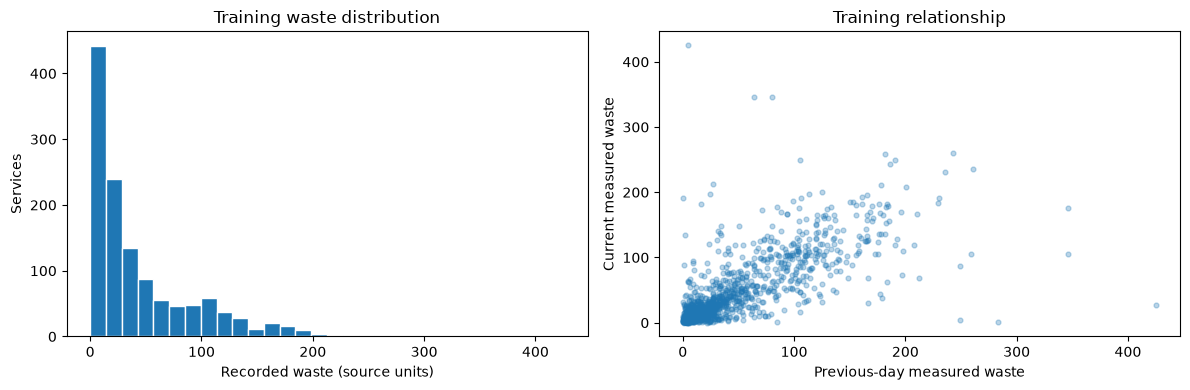

In [5]:
# Inspect TRAINING data only before model selection.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(training[TARGET], bins=30, edgecolor='white')
axes[0].set(xlabel='Recorded waste (source units)', ylabel='Services', title='Training waste distribution')
axes[1].scatter(training['lag_1'], training[TARGET], alpha=0.3, s=12)
axes[1].set(xlabel='Previous-day measured waste', ylabel='Current measured waste', title='Training relationship')
plt.tight_layout()
plt.show()

## 5. Train the regression models

`X_train` contains predictor columns; `y_train` contains the actual recorded waste.
**`model.fit(X_train, y_train)` is the training step.** It learns preprocessing
statistics and model parameters from the training partition.

`candidates()` defines pipelines for Ridge Regression, Decision Tree and Random Forest.
Each pipeline one-hot encodes kitchen identity and standardizes numeric inputs before
fitting the regressor. Scaling is particularly relevant to Ridge's coefficient penalty.

Ridge is linear regression with an **L2 penalty** on coefficient magnitude. Here
`alpha=10.0` is a fixed penalty strength, not a tuned optimum. `predict()` applies the
learned pipeline to validation inputs; negative estimates are clipped to zero because
waste is nonnegative.

In [6]:
# X contains the input features; y contains the measured value to predict.
X_train = training[FEATURES]
y_train = training[TARGET]
X_validation = validation[FEATURES]
y_validation = validation[TARGET]

models = candidates()
validation_results = {}
for name, model in models.items():
    # Learn the encoder/scaler statistics and regressor parameters on training only.
    model.fit(X_train, y_train)
    validation_prediction = np.maximum(0, model.predict(X_validation))
    validation_results[name] = scores(y_validation, validation_prediction)
    print(f'Trained {name}: validation MAE = {validation_results[name]["MAE"]:.3f}')

Trained Ridge Regression: validation MAE = 12.650
Trained Decision Tree: validation MAE = 15.461


Trained Random Forest: validation MAE = 13.141


## 6. Compare validation results and select the ML model

The baselines repeat yesterday's waste, average up to seven earlier measurements,
or use the kitchen's historical mean. They require no fitted regression coefficients.

The project selects the lowest **validation MAE among trained ML candidates**,
which selects Ridge Regression on this dataset. The seven-observation mean has
slightly lower validation MAE and remains visible as a benchmark. Ridge is therefore
the best validated ML candidate here, not the best of all forecasting methods.

**Metrics:** MAE is average absolute error; RMSE penalizes larger errors more strongly.
Both use the target's units and lower is better. R² compares squared error with a
mean-target reference, can be negative, and is not classification accuracy.

In [7]:
for name, feature in BASELINES.items():
    validation_results[name] = scores(y_validation, validation[feature])
comparison = pd.DataFrame(validation_results).T.sort_values('MAE')
display(comparison)
# Compare trained ML models only; baselines remain visible benchmarks.
best_ml_name = min(models, key=lambda name: validation_results[name]['MAE'])
selected_name = best_ml_name
print('Best ML candidate by validation MAE:', best_ml_name)
print('Selected ML model:', selected_name)

,MAE,RMSE,R2
Recent 7 observations mean,12.581987,20.430261,0.775225
Ridge Regression,12.650014,20.060314,0.783292
Random Forest,13.140739,20.746290,0.768218
Historical mean,14.774358,22.833510,0.719234
Previous day,15.458573,25.789162,0.641842
Decision Tree,15.460808,24.522564,0.676159


Best ML candidate by validation MAE: Ridge Regression
Selected ML model: Ridge Regression


## 7. Refit the selected model and evaluate the holdout

After selecting the ML candidate, fit a fresh copy of its pipeline on the combined
training and validation partitions. This refit includes the encoder and scaler.
The test targets are not used to fit the saved pipeline. Test scoring includes only
kitchens represented in this combined fit.

**Rolling next-day evaluation:** earlier test-day actual measurements may inform
features for later test-day forecasts, as they would become available in daily use.
The model weights stay fixed. This is not a multi-day forecast made without new
measurements. The test period was previously inspected and is not a fresh holdout.

In [8]:
fit_rows = pd.concat([training, validation_all], ignore_index=True)
test = test_all[test_all.kitchen.isin(fit_rows.kitchen.unique())].copy()
final_model = None
if selected_name in models:
    # Start a fresh pipeline, then fit on train + validation without test targets.
    final_model = clone(models[selected_name])
    final_model.fit(fit_rows[FEATURES], fit_rows[TARGET])

payload = {
    'model': final_model, 'selected_name': selected_name, 'features': FEATURES,
    'unit': UNIT, 'known_kitchens': sorted(fit_rows.kitchen.unique().tolist()),
    'training_last_date': str(fit_rows.date.max().date()),
    'evaluation_protocol': 'rolling next-day, previous calendar-day measurement required',
}
# Apply the fixed fitted pipeline; do not fit it on the test partition.
test_prediction = predict_selected(payload, test[FEATURES])
test_results = {name: scores(test[TARGET], test[feature]) for name, feature in BASELINES.items()}
test_results[selected_name] = scores(test[TARGET], test_prediction)
print('Scored final test records:', len(test))
print('Excluded unseen-kitchen test records:', len(test_all) - len(test))
display(pd.DataFrame(test_results).T)
baseline_mae = test_results['Previous day']['MAE']
improvement = 100 * (1 - test_results[selected_name]['MAE'] / baseline_mae)
print(f'MAE improvement over previous-day baseline: {improvement:.1f}%')

Scored final test records: 669
Excluded unseen-kitchen test records: 31


,MAE,RMSE,R2
Previous day,13.273244,21.431382,0.649389
Recent 7 observations mean,10.987892,17.603632,0.763447
Historical mean,15.564342,22.589765,0.610464
Ridge Regression,10.808933,17.381763,0.769372


MAE improvement over previous-day baseline: 18.6%


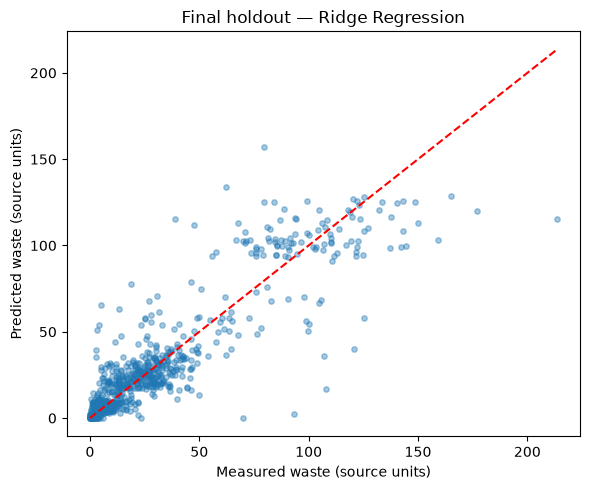

,kitchen,rows,MAE
4,Cyprus / Artisan Burger Bar,1,70.000000
20,kavala / Paraliakon,2,30.275774
15,Santander / Restaurante Machichaco,26,27.025985
19,Tenerife / Tiagaiga,50,22.328706
16,Tenerife / El Tope,52,20.670935
3,Copenhagen / Steelhouse,2,19.676631
7,Cyprus / Hilton Cyprus,15,18.896997
17,Tenerife / Marte,50,18.694201
12,Portugal / Tivoli Oriente,48,11.297993
6,Cyprus / CU Ledras,44,8.981121


In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(test[TARGET], test_prediction, alpha=0.4, s=15)
limit = max(test[TARGET].max(), test_prediction.max())
ax.plot([0, limit], [0, limit], 'r--')
ax.set(xlabel='Measured waste (source units)', ylabel='Predicted waste (source units)',
       title=f'Final holdout — {selected_name}')
plt.tight_layout()
plt.show()

per_kitchen = pd.DataFrame([
    {'kitchen': kitchen, 'rows': len(group),
     'MAE': float(np.mean(np.abs(group[TARGET] - group.predicted)))}
    for kitchen, group in test.assign(predicted=test_prediction).groupby('kitchen')
])
display(per_kitchen.sort_values('MAE', ascending=False))

## 8. Save the notebook-trained model and metadata

Save the fitted pipeline, feature schema, known kitchens, training cutoff, metrics,
data checksum and software versions. Notebook artifacts have separate names from
the command-line artifacts. The dashboard can load either saved run and prefers the
notebook artifact when both exist.

Saving the entire pipeline ensures prediction uses the same encoding and scaling
learned during fitting. Only load pickle artifacts from trusted sources.

In [10]:
output = ROOT / 'model'
output.mkdir(exist_ok=True)
metrics = {
    'source': 'https://zenodo.org/records/3355300',
    'source_sha256': hashlib.sha256(RAW_PATH.read_bytes()).hexdigest(),
    'unit': UNIT, 'selected_name': selected_name,
    'validation_results': validation_results, 'test_results': test_results,
    'test_rows': len(test), 'fit_last_date': payload['training_last_date'],
    'test_first_date': str(test.date.min().date()), 'test_last_date': str(test.date.max().date()),
    'protocol': payload['evaluation_protocol'],
    'versions': {'python': platform.python_version(), 'pandas': pd.__version__,
                 'numpy': np.__version__, 'scikit_learn': sklearn.__version__},
}
payload['metrics'] = metrics
with (output / 'real_notebook_model.pkl').open('wb') as f:
    pickle.dump(payload, f)
(output / 'real_notebook_metrics.json').write_text(json.dumps(metrics, indent=2, allow_nan=False) + '\n')
print('Saved:', output / 'real_notebook_model.pkl')

Saved: /Users/namitachhabra/Documents/zerowaste/model/real_notebook_model.pkl


## 9. Generate one historical next-day forecast

Load the saved artifact and predict waste for Copenhagen / Axel on 22 November 2018.
Only earlier measurements are used. The forecast function rejects dates within the
fitting period, unknown kitchens and history without a previous-day measurement.

This is a historical example. A present-day forecast requires updated measurements;
reliability in current operations must be evaluated separately.

In [11]:
with (ROOT / 'model/real_notebook_model.pkl').open('rb') as f:
    saved = pickle.load(f)
display(forecast(saved, clean, 'Copenhagen / Axel', '2018-11-22'))

{'kitchen': 'Copenhagen / Axel',
 'forecast_date': '2018-11-22',
 'predicted_waste': 28.456,
 'unit': 'source weight units (exact CSV unit unconfirmed)',
 'selected_model': 'Ridge Regression',
 'history_last_date': '2018-11-21',
 'notice': 'Historical-data prototype; no kg, financial-loss or preparation claim until unit confirmation.'}

## Interpretation and project limitations

- Models are trained on recorded observations, not synthetically generated targets.
- Ridge Regression is selected by validation MAE among the trained ML candidates.
  The moving-average baseline has slightly lower validation MAE.
- Test metrics describe an existing holdout inspected in earlier experiments; this
  revision does not establish performance on a fresh independent dataset.
- Results concern the covered kitchens' 2018 records. They do not establish reliability
  for new restaurants, present-day Indian kitchens or unrecorded services.
- Aggregate R² may reflect differences between kitchens. Inspect per-kitchen errors
  alongside overall metrics.
- The export's exact weight unit is unconfirmed; financial losses and preparation
  recommendations are outside the validated scope.
- Further changes based on test performance require a fresh holdout for an independent
  assessment.